In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("Iris.csv")
print(df.head())

   Id  SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm      Species
0   1            5.1           3.5            1.4           0.2  Iris-setosa
1   2            4.9           3.0            1.4           0.2  Iris-setosa
2   3            4.7           3.2            1.3           0.2  Iris-setosa
3   4            4.6           3.1            1.5           0.2  Iris-setosa
4   5            5.0           3.6            1.4           0.2  Iris-setosa


In [3]:
print("Rows:", df.shape[0], "Columns:", df.shape[1])
print("Columns:", df.columns.tolist())
df.info()
print("Missing values per column:\n", df.isnull().sum())

Rows: 150 Columns: 6
Columns: ['Id', 'SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm', 'Species']
<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             150 non-null    int64  
 1   SepalLengthCm  150 non-null    float64
 2   SepalWidthCm   150 non-null    float64
 3   PetalLengthCm  150 non-null    float64
 4   PetalWidthCm   150 non-null    float64
 5   Species        150 non-null    str    
dtypes: float64(4), int64(1), str(1)
memory usage: 9.1 KB
Missing values per column:
 Id               0
SepalLengthCm    0
SepalWidthCm     0
PetalLengthCm    0
PetalWidthCm     0
Species          0
dtype: int64


In [4]:
numeric_df = df.select_dtypes(include=np.number).drop(columns=["Id"], errors="ignore")
print(numeric_df.describe().T)

               count      mean       std  min  25%   50%  75%  max
SepalLengthCm  150.0  5.843333  0.828066  4.3  5.1  5.80  6.4  7.9
SepalWidthCm   150.0  3.054000  0.433594  2.0  2.8  3.00  3.3  4.4
PetalLengthCm  150.0  3.758667  1.764420  1.0  1.6  4.35  5.1  6.9
PetalWidthCm   150.0  1.198667  0.763161  0.1  0.3  1.30  1.8  2.5


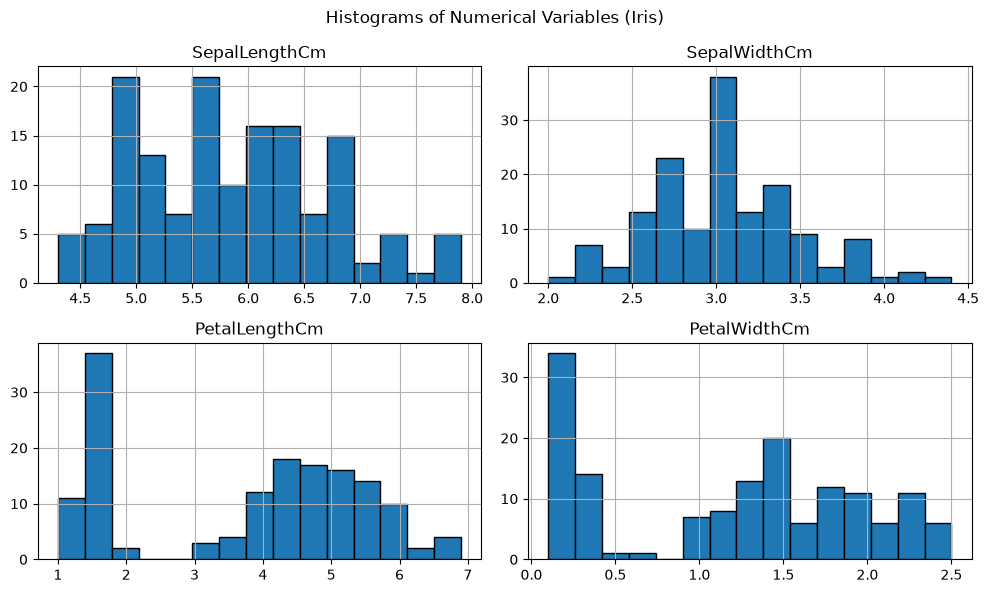

In [5]:
numeric_df.hist(figsize=(10, 6), bins=15, edgecolor="black")
plt.suptitle("Histograms of Numerical Variables (Iris)")
plt.tight_layout()
plt.show()

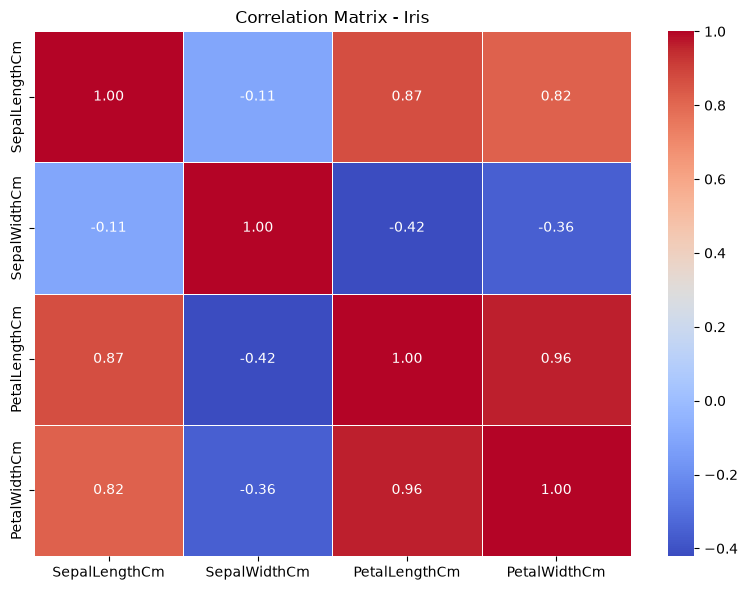

In [6]:
corr = numeric_df.corr()
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", linewidths=0.5)
plt.title("Correlation Matrix - Iris")
plt.tight_layout()
plt.show()

In [7]:
mask = np.triu(np.ones(corr.shape, dtype=bool), k=1)
pairs = corr.where(mask).stack()
print("Top correlated variable pairs:")
print(pairs.sort_values(key=abs, ascending=False).head(10))

Top correlated variable pairs:
PetalLengthCm  PetalWidthCm     0.962757
SepalLengthCm  PetalLengthCm    0.871754
               PetalWidthCm     0.817954
SepalWidthCm   PetalLengthCm   -0.420516
               PetalWidthCm    -0.356544
SepalLengthCm  SepalWidthCm    -0.109369
               SepalLengthCm         NaN
SepalWidthCm   SepalLengthCm         NaN
               SepalWidthCm          NaN
PetalLengthCm  SepalLengthCm         NaN
dtype: float64
